##Создание файла с  новыми СКЮ по заданному шаблону

**Задача:** есть файл клиента (maket) с заданными полями. Нужно дополнить его новинками из портала или тулза и проставить статус (обучен продукт или пока еще находится в обучении).

**Как будем решать:** Загрузим 2 файла (portal и  tools), в каждом из которых частично содержатся нужные поля для макета. Отфильтруем только активные СКЮ из тулза. Соединим датафреймы tools и maket внешним левым соединением и оставим только те продукты, которые есть в датафрейме tools (это и есть новинки). Дополним получившийся датафрейм с новинками new недостающими колонками: соединим его c датафреймом portal (содержащим недостающие колонки) левым соединением по product_id. Добавим поле status, где проставим статусы "Обучен" или "В обучении" (условие: обучен, если подтверждено > 15 фейсов).

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [51]:
%load_ext google.colab.data_table

The google.colab.data_table extension is already loaded. To reload it, use:
  %reload_ext google.colab.data_table


In [52]:
#Загружаем список  СКЮ из Макетов
maket=pd.read_excel('https://raw.githubusercontent.com/ElenaLuchnikova/Datasets/refs/heads/main/maket.xlsx')
#Загружаем список СКЮ с портала
portal=pd.read_excel('https://raw.githubusercontent.com/ElenaLuchnikova/Datasets/refs/heads/main/SKU_portal.xlsx')
#Загружаем список СКЮ из тулза
tools=pd.read_csv('https://raw.githubusercontent.com/ElenaLuchnikova/Datasets/refs/heads/main/SKU_tools.csv', encoding='1251', sep=';', on_bad_lines='skip')

pd.set_option('display.max_columns', 50)


In [53]:
pd.set_option('display.float_format', '{:.0f}'.format)

In [ ]:
maket.head()

In [ ]:
portal.info()

In [ ]:
tools.head()

In [57]:
tools['product.is_active'].astype('int64')

,product.is_active
0,1
1,0
2,0
3,0
4,0
...,...
6245,0
6246,0
6247,1
6248,0


In [ ]:
#Оставляем только активные СКЮ
tools=tools[tools['product.is_active']==1]
tools.info()

In [59]:
#Переназовем столбец
maket=maket.rename(columns={'product_id': 'product.id'})

In [60]:
#Сливаем датафремы в один по ключу id
new = tools.merge(maket, how = 'left', on = 'product.id', indicator=True)

In [ ]:
new.head()

In [62]:
#Оставляем только новинки (те строки, которые присутствуют только в датафрейме tools)
new=new[new['_merge']=='left_only']

In [ ]:
new.info()

In [64]:
portal_cols= ['product_id', 'external_product_id', 'external_base_id', 'product_name', 'product_size_name', 'category_name', 'brand_owner_name', 'brand_name', 'klass_code', 'product_other']

In [65]:
#Оставляем только необходимые колонки (портал)
portal=portal[portal_cols]


In [66]:
#d={False:0, True:1}
#portal['other']=portal['other'].map(d)
#portal['is_active']=portal['is_active'].map(d)

In [67]:
new_cols=['product.id', 'package_type.code',  'dset.confirmedBoxes', 'product.is_active']

In [68]:
#Оставляем только необходимые колонки (тулз)
new=new[new_cols]
new.info()

<class 'pandas.core.frame.DataFrame'>
Index: 37 entries, 114 to 1013
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product.id           37 non-null     object
 1   package_type.code    37 non-null     object
 2   dset.confirmedBoxes  37 non-null     int64 
 3   product.is_active    37 non-null     int64 
dtypes: int64(2), object(2)
memory usage: 1.4+ KB


In [69]:
#Меняем название колонки с id
portal = portal.rename(columns={'product_id': 'product.id'})
portal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6069 entries, 0 to 6068
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product.id           6069 non-null   object 
 1   external_product_id  1053 non-null   object 
 2   external_base_id     161 non-null    float64
 3   product_name         6069 non-null   object 
 4   product_size_name    6069 non-null   object 
 5   category_name        6069 non-null   object 
 6   brand_owner_name     6069 non-null   object 
 7   brand_name           6069 non-null   object 
 8   klass_code           6069 non-null   object 
 9   product_other        6069 non-null   int64  
dtypes: float64(1), int64(1), object(8)
memory usage: 474.3+ KB


In [70]:
#Сливаем датафремы new и portal в один по ключу id
df3 = new.merge(portal, how = 'left', on = 'product.id')

In [71]:
df3.head(3)

,product.id,package_type.code,dset.confirmedBoxes,product.is_active,external_product_id,external_base_id,product_name,product_size_name,category_name,brand_owner_name,brand_name,klass_code,product_other
0,5aec1da7b80b8-7445,gb,0,1,232224719265212,NaN,Вино Пичини Кьянти Классико Ризерва DOCG кр су...,0.75,Вино_bel,Beluga,Пичини,pichini_kyanti_klassiko_rizerva_kr_suh_gb,0
1,69a95632a6c47-2250,gb,0,1,232224719264619,NaN,Вино игристое Фаустино Кава Риоха DO бел п/сух...,0.75,Вино игристое_bel,Beluga,Фаустино,faustino_kava_rioha_do_bel_p_suh_gb,0
2,69a958a2c6eb7-6954,cardboard_box,15,1,232224719272042,NaN,"Ром Плантерей Гран Аньехо Гватемала и Белиз 0,...",0.7,Ром_bel,Beluga,Planteray,planteray_gran_anejo_guatemala_belize_cardboar...,0


In [ ]:
df3.info()

In [73]:
#Добавляем дополнительные колонки и проставляем статус обученности в зависимости от кол-ва подтвержденных фейсов (Обучен, если подтверждено >=  15 фейсов)
df3['faces']='20-40'
df3['status']=np.where(df3['dset.confirmedBoxes'] >= 15, 'Обучен', 'В обучении')


In [74]:
df3.head(1)

,product.id,package_type.code,dset.confirmedBoxes,product.is_active,external_product_id,external_base_id,product_name,product_size_name,category_name,brand_owner_name,brand_name,klass_code,product_other,faces,status
0,5aec1da7b80b8-7445,gb,0,1,232224719265212,NaN,Вино Пичини Кьянти Классико Ризерва DOCG кр су...,0.75,Вино_bel,Beluga,Пичини,pichini_kyanti_klassiko_rizerva_kr_suh_gb,0,20-40,В обучении


In [ ]:
#Заменим Nan на 0 в столбце 'dset.confirmedBoxes'
df3['dset.confirmedBoxes'].fillna(0, inplace=True)

In [ ]:
df3.info()

In [77]:
#Поставим столбцы в корректном порядке
new_order=['product.id','external_product_id','external_base_id','product_name', 'product_size_name', 'package_type.code', 'category_name', 'brand_owner_name', 'brand_name', 'klass_code', 'dset.confirmedBoxes', 'faces','status','product_other','product.is_active']
df3=df3.reindex(columns=new_order)

In [ ]:
df3

In [79]:
df3_gr=df3.groupby('status')['product.id'].count().reset_index()
df3_gr

,status,product.id
0,В обучении,27
1,Обучен,10


<BarContainer object of 2 artists>

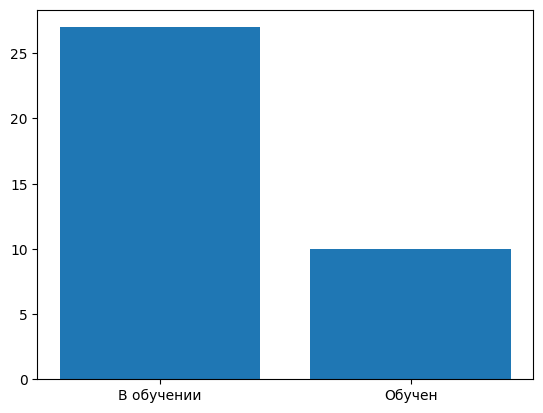

In [80]:
#Сравним количество обученных и необученных СКЮ
plt.bar(df3_gr['status'], df3_gr['product.id'])

In [81]:
#Скачиваем файл с новинками в Excel
#df3.to_excel("Novabev_SKU.xlsx")